
# Notebook 15: Before vs After Preprocessing

## Objective
Compare a raw dataset with its preprocessed version and understand
how data cleaning and preprocessing improve data quality.

## Learning Outcomes
- Compare dataset shapes before and after preprocessing.
- Identify changes in data types.
- Compare missing values and duplicate records.
- Analyze outliers before and after preprocessing.
- Compare numerical distributions and ranges.
- Examine categorical values and encoded features.
- Visualize preprocessing results.
- Explain the impact of each preprocessing technique.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

n = 100

df_raw = pd.DataFrame({
    "Age": np.random.randint(21, 60, n),
    "Salary": np.random.randint(20000, 100000, n),
    "Experience": np.random.randint(0, 25, n),
    "Department": np.random.choice(
        ["IT", "HR", "Finance", "Marketing"], n
    ),
    "Education": np.random.choice(
        ["Graduate", "Postgraduate", "PhD"], n
    )
})

# Introduce missing values.
df_raw.loc[[2, 10, 20, 30], "Age"] = np.nan
df_raw.loc[[5, 15, 25], "Salary"] = np.nan
df_raw.loc[[8, 18], "Department"] = np.nan

# Introduce extreme values.
df_raw.loc[0, "Salary"] = 500000
df_raw.loc[1, "Age"] = 120

# Introduce exact duplicate records.
df_raw = pd.concat(
    [df_raw, df_raw.iloc[[3, 7, 12]]],
    ignore_index=True
)

print("Raw dataset created successfully!")
print("Dataset shape:", df_raw.shape)

display(df_raw.head(10))

Raw dataset created successfully!
Dataset shape: (103, 5)


,Age,Salary,Experience,Department,Education
0,59.0,500000.0,10,Marketing,Graduate
1,120.0,30965.0,24,IT,Graduate
2,NaN,44538.0,24,IT,Graduate
3,28.0,90592.0,17,HR,PhD
4,41.0,28110.0,22,IT,Postgraduate
5,59.0,NaN,9,Finance,Graduate
6,39.0,47266.0,2,Finance,Postgraduate
7,43.0,72992.0,6,Marketing,PhD
8,31.0,26910.0,15,NaN,PhD
9,31.0,20206.0,15,Marketing,PhD


In [3]:
print("Dataset information:")
df_raw.info()

print("\nDescriptive statistics:")
display(df_raw.describe(include="all"))

print("\nMissing values:")
display(df_raw.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate records:", df_raw.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         99 non-null     float64
 1   Salary      100 non-null    float64
 2   Experience  103 non-null    int32  
 3   Department  101 non-null    str    
 4   Education   103 non-null    str    
dtypes: float64(2), int32(1), str(2)
memory usage: 5.1 KB

Descriptive statistics:


,Age,Salary,Experience,Department,Education
count,99.000000,100.000000,103.000000,101,103
unique,NaN,NaN,NaN,4,3
top,NaN,NaN,NaN,HR,Graduate
freq,NaN,NaN,NaN,32,39
mean,39.919192,64366.230000,11.757282,NaN,NaN
std,13.737835,49310.783811,7.744025,NaN,NaN
min,21.000000,20206.000000,0.000000,NaN,NaN
25%,29.000000,42218.250000,4.000000,NaN,NaN
50%,40.000000,63923.500000,13.000000,NaN,NaN
75%,47.500000,78811.500000,18.000000,NaN,NaN



Missing values:


,Missing_Count
Age,4
Salary,3
Experience,0
Department,2
Education,0



Duplicate records: 3



## 1. Dataset Shape

Dataset shape represents:
- Number of rows (observations).
- Number of columns (features).

Preprocessing can change the number of rows by removing duplicate
records and the number of columns through encoding or feature
selection.


In [4]:
print("Before preprocessing:")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

# Remove exact duplicate records.
df_clean = df_raw.drop_duplicates().copy()

print("\nAfter duplicate removal:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Before preprocessing:
Rows: 103
Columns: 5

After duplicate removal:
Rows: 100
Columns: 5


In [5]:
print("Data types before preprocessing:")
display(df_raw.dtypes.to_frame("Before"))

print("\nData types after duplicate removal:")
display(df_clean.dtypes.to_frame("After"))

Data types before preprocessing:


,Before
Age,float64
Salary,float64
Experience,int32
Department,str
Education,str



Data types after duplicate removal:


,After
Age,float64
Salary,float64
Experience,int32
Department,str
Education,str


In [6]:
missing_before = df_raw.isnull().sum()
missing_after_dedup = df_clean.isnull().sum()

missing_comparison = pd.DataFrame({
    "Before": missing_before,
    "After_Duplicate_Removal": missing_after_dedup
})

display(missing_comparison)

,Before,After_Duplicate_Removal
Age,4,4
Salary,3,3
Experience,0,0
Department,2,2
Education,0,0


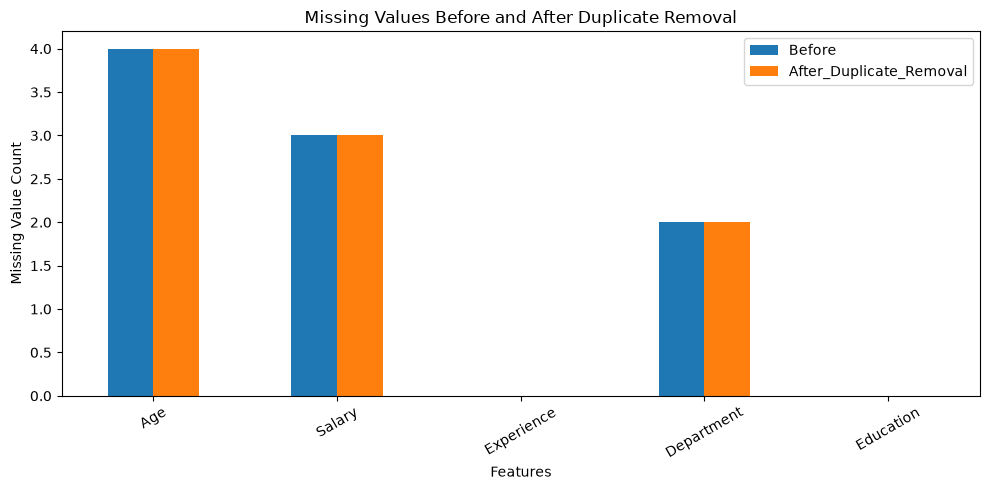

In [7]:
missing_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Missing Values Before and After Duplicate Removal")
plt.xlabel("Features")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
duplicates_before = df_raw.duplicated().sum()
duplicates_after = df_clean.duplicated().sum()

duplicate_summary = pd.DataFrame({
    "Stage": ["Before preprocessing", "After duplicate removal"],
    "Duplicate_Count": [
        duplicates_before,
        duplicates_after
    ]
})

display(duplicate_summary)

print("Remaining duplicates:", df_clean.duplicated().sum())

,Stage,Duplicate_Count
0,Before preprocessing,3
1,After duplicate removal,0


Remaining duplicates: 0



## 2. Outlier Analysis

Outliers are observations that differ significantly from the
general pattern of the dataset.

We will use the Interquartile Range (IQR) method.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these boundaries are flagged as potential outliers.

Important:
Scaling does not automatically remove outliers. A valid extreme
observation should not be deleted without investigation.


In [9]:
def count_outliers_iqr(series):
    series = series.dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    return count, lower_bound, upper_bound


for column in ["Age", "Salary", "Experience"]:
    count, lower, upper = count_outliers_iqr(
        df_clean[column]
    )

    print(f"\n{column}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Potential outliers:", count)


Age
Lower bound: 0.5
Upper bound: 76.5
Potential outliers: 1

Salary
Lower bound: -12139.5
Upper bound: 132168.5
Potential outliers: 1

Experience
Lower bound: -17.38
Upper bound: 39.62
Potential outliers: 0


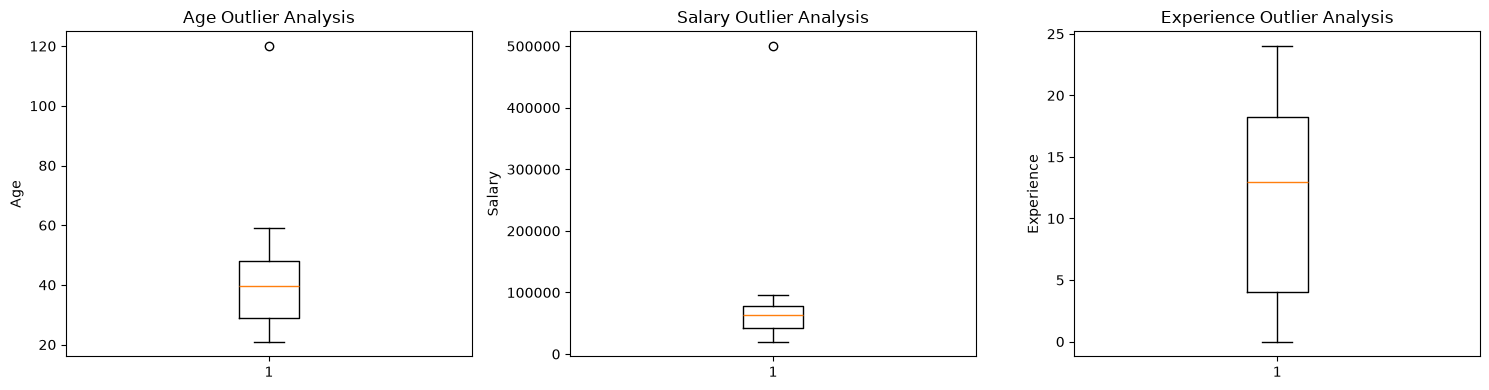

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(
    axes,
    ["Age", "Salary", "Experience"]
):
    ax.boxplot(df_clean[column].dropna())
    ax.set_title(f"{column} Outlier Analysis")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

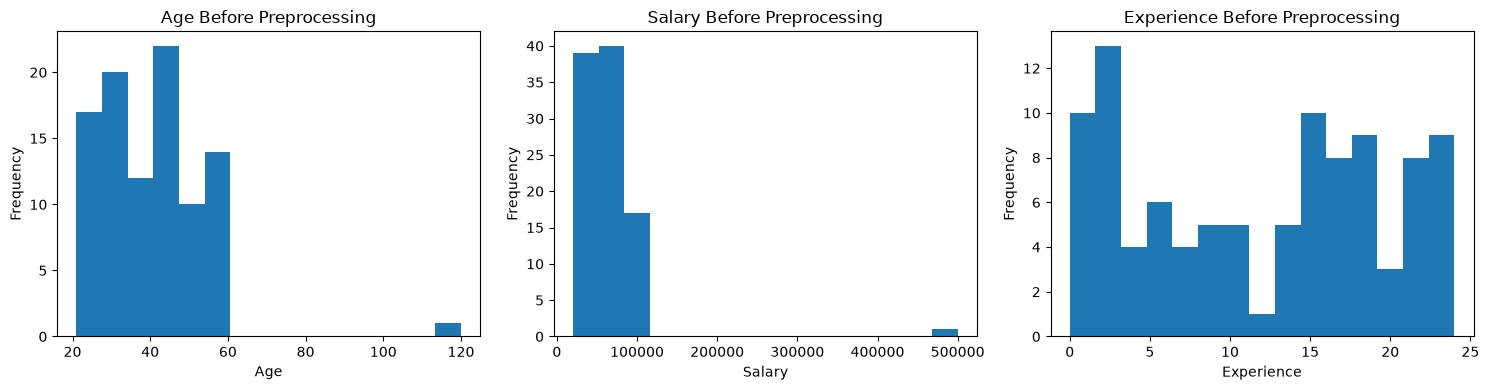

In [11]:
numerical_columns = [
    "Age",
    "Salary",
    "Experience"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numerical_columns):
    ax.hist(df_clean[column].dropna(), bins=15)
    ax.set_title(f"{column} Before Preprocessing")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [12]:
categorical_columns = [
    "Department",
    "Education"
]

for column in categorical_columns:
    print(f"\nCategory distribution: {column}")
    display(
        df_clean[column]
        .value_counts(dropna=False)
        .to_frame("Count")
    )


Category distribution: Department


,Count
Department,
HR,31
Finance,25
Marketing,22
IT,20
NaN,2



Category distribution: Education


,Count
Education,
Graduate,39
Postgraduate,34
PhD,27


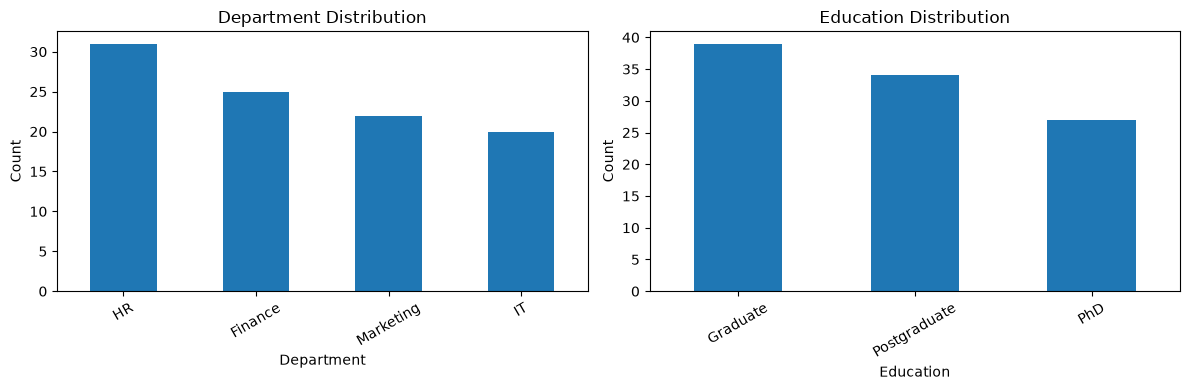

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column in zip(axes, categorical_columns):
    df_clean[column].value_counts().plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"{column} Distribution")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [14]:
X = df_clean.copy()

X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

print("Training dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

Training dataset shape: (80, 5)
Testing dataset shape: (20, 5)


In [15]:
numerical_features = [
    "Age",
    "Salary",
    "Experience"
]

categorical_features = [
    "Department",
    "Education"
]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
# Fit using training data only.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned transformations to test data.
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (80, 5)
Processed training shape: (80, 10)

Original testing shape: (20, 5)
Processed testing shape: (20, 10)


In [17]:
feature_names = preprocessor.get_feature_names_out()

if hasattr(X_train_processed, "toarray"):
    train_array = X_train_processed.toarray()
else:
    train_array = np.asarray(X_train_processed)

if hasattr(X_test_processed, "toarray"):
    test_array = X_test_processed.toarray()
else:
    test_array = np.asarray(X_test_processed)

df_train_after = pd.DataFrame(
    train_array,
    columns=feature_names,
    index=X_train.index
)

df_test_after = pd.DataFrame(
    test_array,
    columns=feature_names,
    index=X_test.index
)

print("Processed training dataset:")
display(df_train_after.head())

print("Processed test dataset:")
display(df_test_after.head())

Processed training dataset:


,numerical__Age,numerical__Salary,numerical__Experience,categorical__Department_Finance,categorical__Department_HR,categorical__Department_IT,categorical__Department_Marketing,categorical__Education_Graduate,categorical__Education_PhD,categorical__Education_Postgraduate
55,-0.205365,1.264541,-1.562572,0.0,0.0,0.0,1.0,0.0,0.0,1.0
88,-1.125965,0.421072,0.815973,0.0,1.0,0.0,0.0,0.0,1.0,0.0
26,0.502790,0.388670,-1.298289,0.0,0.0,0.0,1.0,0.0,1.0,0.0
42,-0.063734,0.933563,0.419549,0.0,0.0,1.0,0.0,0.0,1.0,0.0
69,0.219528,0.681218,-0.109017,0.0,1.0,0.0,0.0,0.0,0.0,1.0


Processed test dataset:


,numerical__Age,numerical__Salary,numerical__Experience,categorical__Department_Finance,categorical__Department_HR,categorical__Department_IT,categorical__Department_Marketing,categorical__Education_Graduate,categorical__Education_PhD,categorical__Education_Postgraduate
83,-0.276180,-0.781920,-1.562572,0.0,1.0,0.0,0.0,1.0,0.0,0.0
53,-1.196781,1.472427,-0.505441,0.0,1.0,0.0,0.0,1.0,0.0,0.0
70,0.361159,0.283929,0.815973,0.0,0.0,0.0,1.0,1.0,0.0,0.0
45,-0.913519,-1.366883,1.608821,0.0,1.0,0.0,0.0,0.0,0.0,1.0
44,-0.984334,0.651786,-1.298289,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [18]:
range_comparison = pd.DataFrame({
    "Before_Min": X_train[numerical_features].min(),
    "Before_Max": X_train[numerical_features].max(),
    "After_Min": df_train_after[
        [f"numerical__{col}" for col in numerical_features]
    ].min().values,
    "After_Max": df_train_after[
        [f"numerical__{col}" for col in numerical_features]
    ].max().values
}, index=numerical_features)

display(range_comparison.round(3))

,Before_Min,Before_Max,After_Min,After_Max
Age,21.0,120.0,-1.409,5.602
Salary,20206.0,95766.0,-1.778,1.572
Experience,0.0,24.0,-1.563,1.609


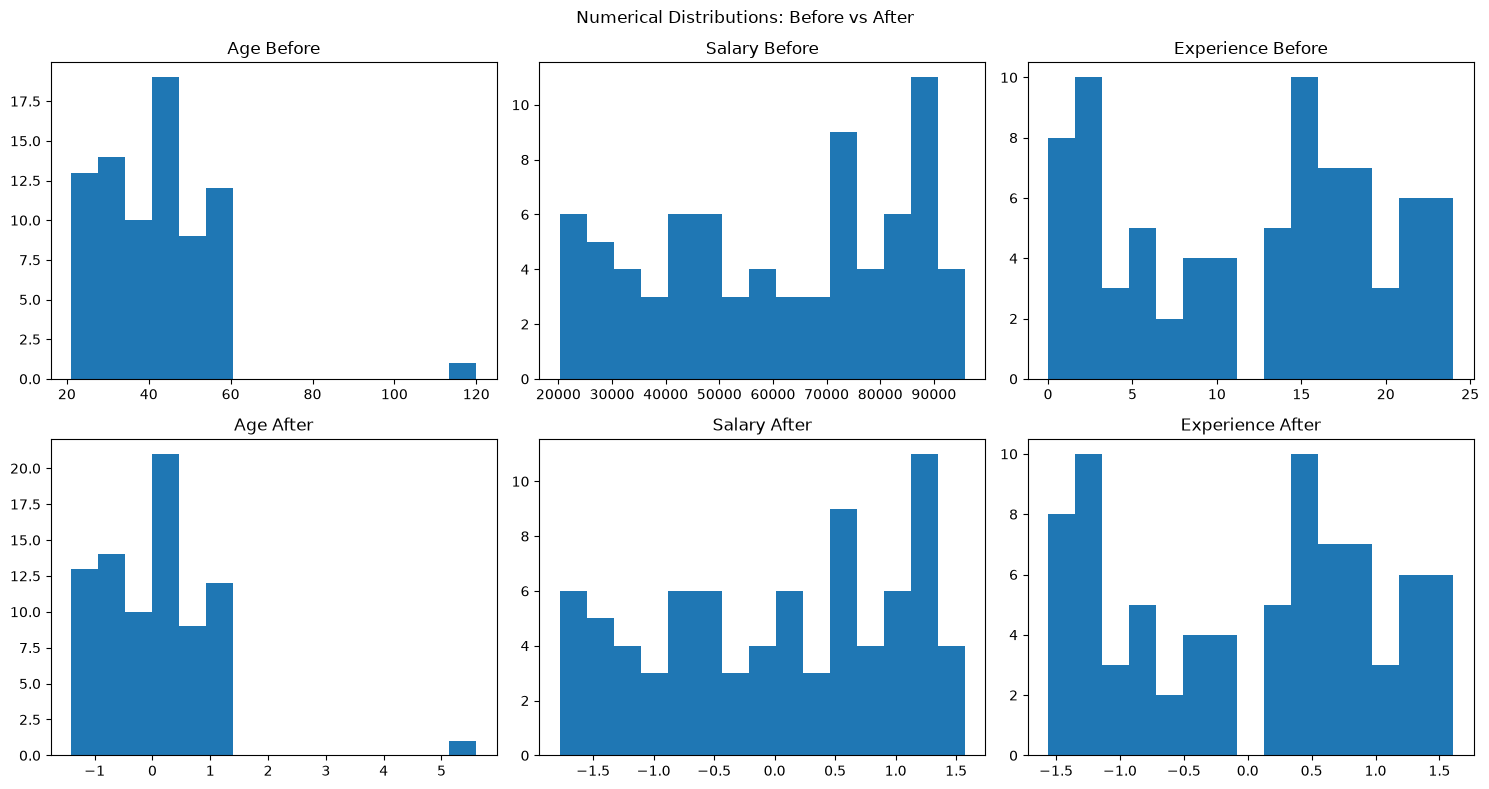

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, column in enumerate(numerical_features):
    processed_column = f"numerical__{column}"

    axes[0, i].hist(
        X_train[column].dropna(),
        bins=15
    )
    axes[0, i].set_title(f"{column} Before")

    axes[1, i].hist(
        df_train_after[processed_column],
        bins=15
    )
    axes[1, i].set_title(f"{column} After")

plt.suptitle("Numerical Distributions: Before vs After")
plt.tight_layout()
plt.show()

In [20]:
encoded_columns = [
    col for col in df_train_after.columns
    if col.startswith("categorical__")
]

print("Categorical encoded columns:")
print(encoded_columns)

print("\nEncoded dataset:")
display(df_train_after[encoded_columns].head(10))

Categorical encoded columns:
['categorical__Department_Finance', 'categorical__Department_HR', 'categorical__Department_IT', 'categorical__Department_Marketing', 'categorical__Education_Graduate', 'categorical__Education_PhD', 'categorical__Education_Postgraduate']

Encoded dataset:


,categorical__Department_Finance,categorical__Department_HR,categorical__Department_IT,categorical__Department_Marketing,categorical__Education_Graduate,categorical__Education_PhD,categorical__Education_Postgraduate
55,0.0,0.0,0.0,1.0,0.0,0.0,1.0
88,0.0,1.0,0.0,0.0,0.0,1.0,0.0
26,0.0,0.0,0.0,1.0,0.0,1.0,0.0
42,0.0,0.0,1.0,0.0,0.0,1.0,0.0
69,0.0,1.0,0.0,0.0,0.0,0.0,1.0
15,0.0,0.0,1.0,0.0,1.0,0.0,0.0
40,0.0,0.0,1.0,0.0,1.0,0.0,0.0
96,0.0,1.0,0.0,0.0,1.0,0.0,0.0
9,0.0,0.0,0.0,1.0,0.0,1.0,0.0
72,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [21]:
feature_comparison = pd.DataFrame({
    "Stage": [
        "Original Dataset",
        "Processed Dataset"
    ],
    "Feature_Count": [
        X_train.shape[1],
        df_train_after.shape[1]
    ]
})

display(feature_comparison)

print("Original feature count:", X_train.shape[1])
print("Processed feature count:", df_train_after.shape[1])

,Stage,Feature_Count
0,Original Dataset,5
1,Processed Dataset,10


Original feature count: 5
Processed feature count: 10


In [22]:
final_comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Rows",
        "Numerical Columns",
        "Categorical Columns"
    ],
    "Before": [
        X_train.shape[0],
        X_train.shape[1],
        X_train.isnull().sum().sum(),
        X_train.duplicated().sum(),
        len(X_train.select_dtypes(include="number").columns),
        len(X_train.select_dtypes(include=["object", "category"]).columns)
    ],
    "After": [
        df_train_after.shape[0],
        df_train_after.shape[1],
        df_train_after.isnull().sum().sum(),
        df_train_after.duplicated().sum(),
        len(df_train_after.select_dtypes(include="number").columns),
        len(df_train_after.select_dtypes(include=["object", "category"]).columns)
    ]
})

display(final_comparison)

C:\Users\dilee\AppData\Local\Temp\ipykernel_3988\4213765959.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  len(X_train.select_dtypes(include=["object", "category"]).columns)


,Metric,Before,After
0,Rows,80,80
1,Columns,5,10
2,Missing Values,6,0
3,Duplicate Rows,0,0
4,Numerical Columns,3,10
5,Categorical Columns,2,0


In [23]:
outlier_comparison = []

for column in numerical_features:

    before_count, _, _ = count_outliers_iqr(
        X_train[column]
    )

    processed_column = f"numerical__{column}"

    after_count, _, _ = count_outliers_iqr(
        df_train_after[processed_column]
    )

    outlier_comparison.append({
        "Feature": column,
        "Outliers_Before": before_count,
        "Outliers_After": after_count
    })

outlier_comparison_df = pd.DataFrame(outlier_comparison)

display(outlier_comparison_df)

,Feature,Outliers_Before,Outliers_After
0,Age,1,1
1,Salary,0,0
2,Experience,0,0


,Missing Values,Duplicate Rows,Feature Count
Before,6,0,5
After,0,0,10


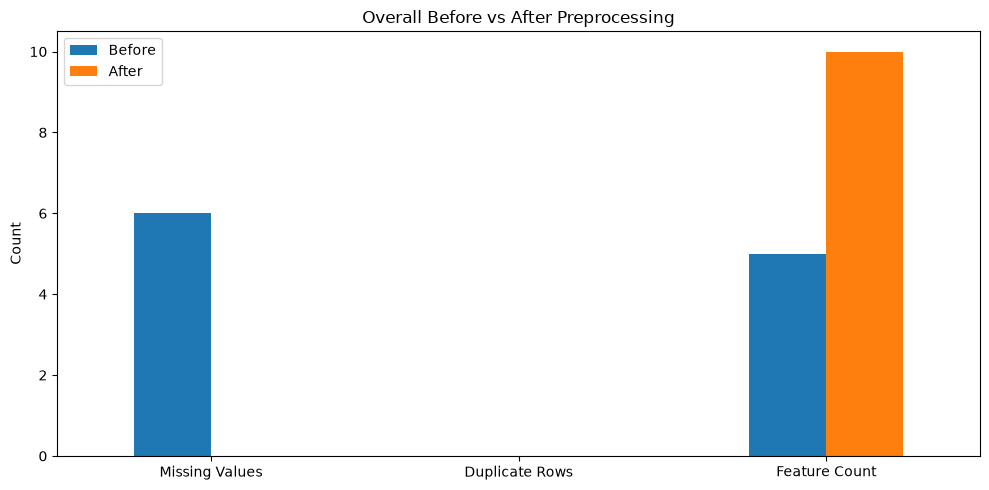

In [24]:
comparison_metrics = {
    "Missing Values": [
        X_train.isnull().sum().sum(),
        df_train_after.isnull().sum().sum()
    ],
    "Duplicate Rows": [
        X_train.duplicated().sum(),
        df_train_after.duplicated().sum()
    ],
    "Feature Count": [
        X_train.shape[1],
        df_train_after.shape[1]
    ]
}

comparison_plot = pd.DataFrame(
    comparison_metrics,
    index=["Before", "After"]
)

display(comparison_plot)

comparison_plot.T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Overall Before vs After Preprocessing")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Before vs After Preprocessing Analysis

### 1. Dataset Shape
Exact duplicate records were removed. One-hot encoding increased
the number of columns.

### 2. Data Types
Original categorical text columns were converted into numerical
binary features.

### 3. Missing Values
Missing numerical values were replaced using the median.
Missing categorical values were replaced using the most frequent
category.

### 4. Duplicates
Exact duplicate records were removed before splitting the dataset.

### 5. Outliers
Extreme observations were identified using the IQR method.
StandardScaler changed their numerical scale but did not remove
them.

### 6. Distributions
Numerical distributions were transformed through standardization.
Their shapes and relative ordering were preserved by this scaling
operation.

### 7. Categorical Values
Categorical features were converted into one-hot encoded columns.

### 8. Numerical Ranges
Numerical features were centered around zero and scaled to
approximately unit variance.

### 9. Feature Count
The feature count increased because categorical variables were
expanded into multiple binary columns.

Overall, preprocessing produced a numerical dataset without
missing values that is ready for further machine learning
development.



## Conclusion

In this notebook, I compared the original dataset with its
preprocessed version.

I analyzed dataset shape, data types, missing values, duplicate
records, outliers, numerical distributions, categorical values,
numerical ranges, and feature counts.

I removed exact duplicate records, handled missing values using
imputation, standardized numerical features, and encoded
categorical features using OneHotEncoder.

I also created visualizations to understand the differences
between the original and processed datasets.

The preprocessing workflow improved data consistency and
converted the raw dataset into a numerical, ML-ready format.

I learned that preprocessing should be performed carefully
because every transformation has a different impact on the data.
